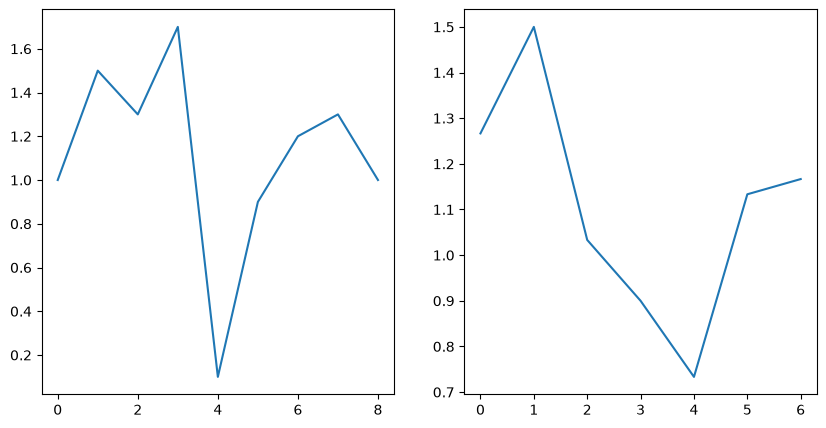

In [25]:
import numpy as np
import matplotlib.pyplot as plt

delta_t = 0.3 #value every 0.1s but unique val every 0.3s (to precision of 2ms)

def select_new_values(data_set):
    out = []
    for row in data_set:
        if row[1] == 1:
            out.append(row[0])
    return np.array(out)

def smooth_values(dataset, average_width = 5, remove_outlier = False, max_deviation = 0.3):
    """
    moving average over all values
    discards start and end values that lie outside of averaging range
    input: 
        average_width: width of moving average (must be odd value)
        data: data set to be smoothed
        remove outlier: True or false, if value deviates a lot -> cancel it
        max_deviation: maximal allowed deviation from moving average -> higher deviation = overwritten, lower deviation = values unchanged

    output:
        smoothed: smoothed data array
    """
    assert(average_width % 2 == 1) #checks odd length
    N = average_width // 2
    L = len(dataset)

    smoothed = np.zeros(L - 2*N)
    for i in range(L - 2*N):
        smoothed[i] = 1/average_width * np.sum(dataset[i: i + 2*N + 1])
    if not remove_outlier:
        return smoothed
    
    data_copy = dataset
    if remove_outlier:
        for i in range(L - 2*N):
            if np.abs(smoothed[i]) <= 0.5:
                continue #condition to aboid division by zero. May need to be adjusted later
            rel_deviation = (dataset[i + N] - smoothed[i])/ abs(smoothed[i])
            if abs(rel_deviation) >= max_deviation:
                data_copy[i + N ] = smooth[i] #outlier value replaced by smoothed value

        resmoothed = np.zeros_like(smooth)
        for i in range(L - 2*N):
            resmoothed[i] = 1/average_width * np.sum(data_copy[i: i + 2*N + 1])
        return resmoothed

test_set = np.array([1, 1.5, 1.3, 1.7, 0.1, 0.9, 1.2, 1.3, 1])
smooth = smooth_values(dataset = test_set, average_width = 3)

fig, ax = plt.subplots(1, 2, figsize = (10,5))
ax[0].plot(np.arange(len(test_set)), test_set)
ax[1].plot(np.arange(len(smooth)), smooth)

Text(0.5, 1.0, 'difference between outlier and non outlier smooth')

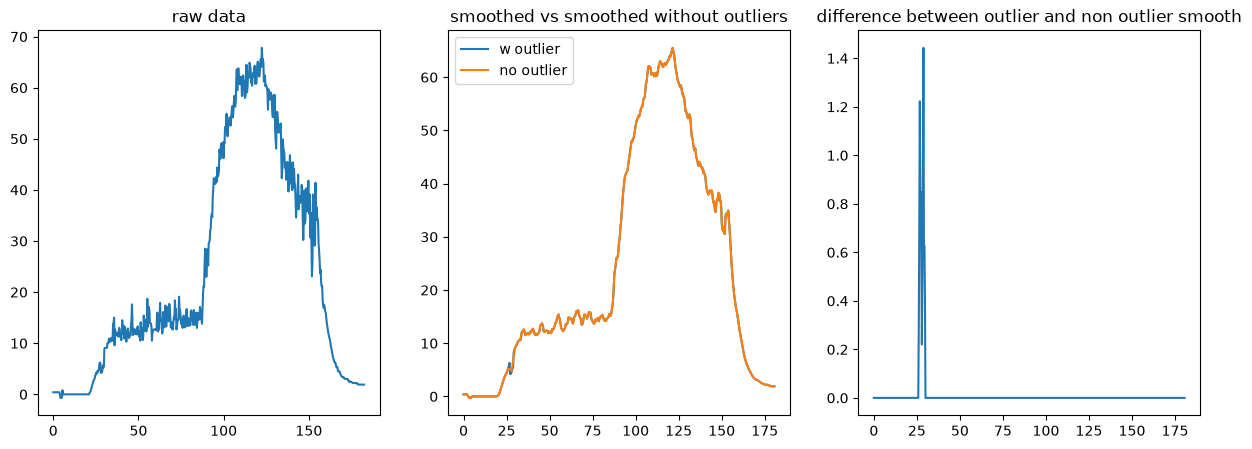

In [29]:
test_run = np.loadtxt("data/test run second cylinder.csv", delimiter = ";", skiprows = 1, usecols = (1,4))
vals_test_run = select_new_values(test_run)
t = delta_t * np.arange(len(vals_test_run))

smooth = smooth_values(vals_test_run, average_width = 7, remove_outlier = False)
smooth_no_outlier = smooth_values(vals_test_run, average_width = 7, remove_outlier = True)
t_s = delta_t * np.arange(len(smooth))

fig, ax = plt.subplots(1, 3, figsize = (15,5))
ax[0].plot(t, vals_test_run)
ax[0].set_title("raw data")
ax[1].plot(t_s, smooth, label = "w outlier")
ax[1].plot(t_s, smooth_no_outlier, label = "no outlier")
ax[1].set_title("smoothed vs smoothed without outliers")
ax[1].legend()
diff = np.abs(smooth - smooth_no_outlier)
ax[2].plot(t_s, diff)
ax[2].set_title("difference between outlier and non outlier smooth")